# **AWS Load Balancer Access Log Analyzer**
# **Log File Frequency Analysis and Visualization using Python**
# **Server Log Analysis: IP Address and HTTP Status Code Report**
# **Python Based ALB Log Analyzer with CSV Export and Bar Chart**

In [16]:


import os
import csv
import pandas as pd
import matplotlib.pyplot as plt

path = "C:\\Users\\admin\\Downloads"
myfile = "mylog.log"

station_ip = []
satellite_status = []

with open(os.path.join(path, myfile)) as f:
    for each in f:
        mylist = each.split()
        station_ip.append(mylist[3].split(":")[0])  # Extracting only the IP address without port
        satellite_status.append(mylist[8])

def frequency(mylist):
    myplanet = {}                                  
    for each in mylist:
        if each not in myplanet:
            myplanet[each] = 1
        else:
            myplanet[each] += 1
    return myplanet

def write_to_csv(mydict, filename, header):
    with open(os.path.join(path, filename), "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["Sno", header, "Frequency"])
        sno = 1
        for each in mydict:
            writer.writerow([sno, each, mydict[each]])
            sno += 1

obj1 = frequency(station_ip)
obj2 = frequency(satellite_status)

write_to_csv(obj1, "station_ip.csv", "station_ip")
write_to_csv(obj2, "satellite_status.csv", "satellite_status")

print("CSV file created successfully")



CSV file created successfully


In [17]:
df_ip = pd.read_csv(os.path.join(path, "station_ip.csv"))
df_status = pd.read_csv(os.path.join(path, "satellite_status.csv"))

df_ip


,Sno,station_ip,Frequency
0,1,192.0.2.88,23
1,2,198.51.100.7,19
2,3,10.0.1.15,19
3,4,10.0.2.22,24
4,5,203.0.113.45,15


In [18]:
df_status

,Sno,satellite_status,Frequency
0,1,200,72
1,2,301,2
2,3,404,9
3,4,502,3
4,5,503,5
5,6,500,9


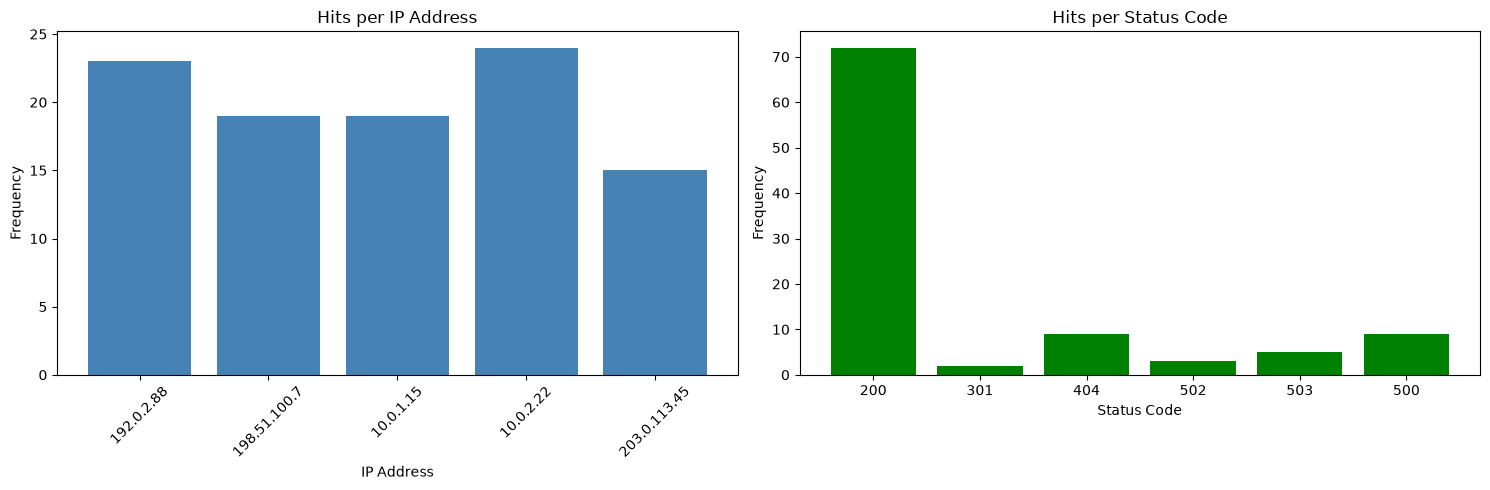

In [21]:
fig, axes = plt.subplots(1,2, figsize=(15,5))

# Left chart: IP address
axes[0].bar(df_ip["station_ip"], df_ip["Frequency"], color="steelblue")
axes[0].set_title("Hits per IP Address")
axes[0].set_xlabel("IP Address")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis="x", rotation=45)

# Right chart: Status code
axes[1].bar(df_status["satellite_status"].astype(str), df_status["Frequency"], color="green")
axes[1].set_title("Hits per Status Code")
axes[1].set_xlabel("Status Code")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(os.path.join(path, "planet_chart.png"))
plt.show()